# 1. Polazni pregled i struktura skupa podataka

## 1.1. Učitavanje i dimenzije skupa podataka

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_sas("LLCP2020.XPT", format="xport", encoding=None)

print("Broj redova:", df.shape[0])
print("Broj kolona:", df.shape[1])

Broj redova: 401958
Broj kolona: 279


## 1.2. Prikaz prvih pet zapisa

In [2]:
display(df.head(5))

df.head(5).to_csv("prvih_5_zapisa.csv", index=False)

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_RFPSA23,_CLNSCPY,_SGMSCPY,_SGMS10Y,_RFBLDS4,_STOLDNA,_VIRCOLN,_SBONTIM,_CRCREC1,_AIDTST4
0,1.0,1.0,b'01042020',b'01',b'04',b'2020',1100.0,b'2020000001',2.020000e+09,1.0,...,NaN,1.0,3.0,3.0,3.0,3.0,3.0,3.0,1.0,1.0
1,1.0,1.0,b'02072020',b'02',b'07',b'2020',1200.0,b'2020000002',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
2,1.0,1.0,b'01232020',b'01',b'23',b'2020',1100.0,b'2020000003',2.020000e+09,1.0,...,NaN,1.0,3.0,3.0,3.0,3.0,3.0,3.0,1.0,2.0
3,1.0,1.0,b'01092020',b'01',b'09',b'2020',1100.0,b'2020000004',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
4,1.0,1.0,b'01042020',b'01',b'04',b'2020',1100.0,b'2020000005',2.020000e+09,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0


## 1.3. Tehnički tipovi i jedinstvene vrijednosti varijabli

In [3]:
pregled = pd.DataFrame({
    "Naziv varijable": df.columns,
    "Tehnicki tip": df.dtypes.astype(str).values,
    "Broj jedinstvenih vrijednosti": df.nunique().values
})

display(pregled)

pregled.to_csv("pregled_varijabli.csv", index=False)

display(df.dtypes.value_counts().to_frame("Broj varijabli"))

print("Broj konstantnih varijabli:", (df.nunique() == 1).sum())
print("Broj potpuno praznih varijabli:", (df.nunique() == 0).sum())

,Naziv varijable,Tehnicki tip,Broj jedinstvenih vrijednosti
0,_STATE,float64,53
1,FMONTH,float64,12
2,IDATE,object,439
3,IMONTH,object,12
4,IDAY,object,31
...,...,...,...
274,_STOLDNA,float64,3
275,_VIRCOLN,float64,3
276,_SBONTIM,float64,3
277,_CRCREC1,float64,3


,Broj varijabli
float64,274
object,5


Broj konstantnih varijabli: 9
Broj potpuno praznih varijabli: 3


## 1.4. Sažeti pregled i značenje varijabli

In [4]:
odabrane_varijable = [
    "_STATE", "IDATE", "SEQNO", "_PSU",
    "SEXVAR", "_AGE80", "EDUCA", "INCOME2",
    "ADDEPEV3", "ACEDEPRS", "ACEDRINK",
    "ACEDRUGS", "ACEPRISN", "ACEDIVRC",
    "ACEPUNCH", "ACEHURT1", "ACESWEAR",
    "ACETOUCH", "ACETTHEM", "ACEHVSEX",
    "CTELENM1", "TOLDCFS"
]

sazeti_pregled = pregled[
    pregled["Naziv varijable"].isin(odabrane_varijable)
]

display(sazeti_pregled)

,Naziv varijable,Tehnicki tip,Broj jedinstvenih vrijednosti
0,_STATE,float64,53
2,IDATE,object,439
7,SEQNO,object,15835
8,_PSU,float64,15835
9,CTELENM1,float64,1
31,SEXVAR,float64,2
51,ADDEPEV3,float64,4
58,EDUCA,float64,7
66,INCOME2,float64,10
130,TOLDCFS,float64,0


## 1.5. Konstantne i gotovo konstantne varijable

In [5]:
konstantne = []

for kolona in df.columns:
    udjeli = df[kolona].value_counts(normalize=True)

    if not udjeli.empty and udjeli.iloc[0] >= 0.95:
        konstantne.append({
            "Varijabla": kolona,
            "Udio najcesce vrijednosti (%)": round(udjeli.iloc[0] * 100, 2),
            "Napomena": "Konstantna" if udjeli.iloc[0] == 1 else "Gotovo konstantna"
        })

konstantne = pd.DataFrame(konstantne)

display(konstantne)

display(konstantne["Napomena"].value_counts().to_frame("Broj varijabli"))

,Varijabla,Udio najcesce vrijednosti (%),Napomena
0,IYEAR,96.98,Gotovo konstantna
1,CTELENM1,100.00,Konstantna
2,PVTRESD1,99.98,Gotovo konstantna
3,COLGHOUS,100.00,Konstantna
4,STATERE1,100.00,Konstantna
5,CELPHONE,100.00,Konstantna
6,LADULT1,99.14,Gotovo konstantna
7,SAFETIME,100.00,Konstantna
8,CTELNUM1,100.00,Konstantna
9,CELLFON5,100.00,Konstantna


,Broj varijabli
Napomena,
Gotovo konstantna,16
Konstantna,9


## 1.6. Provjera jedinstvenosti anketnih zapisa

In [6]:
ponovljeni_identifikatori = df.duplicated(
    subset=["_STATE", "SEQNO"]
).sum()

print("Ukupan broj zapisa:", len(df))

print("Ponovljeni identifikatori:", ponovljeni_identifikatori)

print("Udio ponovljenih identifikatora:",
      round(ponovljeni_identifikatori / len(df) * 100, 2), "%")

Ukupan broj zapisa: 401958
Ponovljeni identifikatori: 0
Udio ponovljenih identifikatora: 0.0 %


# 2. Nedostajući podaci i početna provjera kvaliteta

## 2.1. Pregled nedostajućih vrijednosti

In [7]:
nedostajuci = pd.DataFrame({
    "Varijabla": df.columns,
    "Broj nedostajucih": df.isna().sum().values,
    "Postotak nedostajucih": (
        df.isna().mean() * 100
    ).round(2).values
})

nedostajuci = nedostajuci.sort_values(
    by="Postotak nedostajucih",
    ascending=False
)

display(nedostajuci.head(10))

nedostajuci.to_csv(
    "nedostajuce_vrijednosti.csv",
    index=False
)

print("Broj varijabli bez nedostajucih vrijednosti:",
      (nedostajuci["Broj nedostajucih"] == 0).sum())

print("Broj varijabli s nedostajucim vrijednostima:",
      (nedostajuci["Broj nedostajucih"] > 0).sum())

,Varijabla,Broj nedostajucih,Postotak nedostajucih
130,TOLDCFS,401958,100.00
131,HAVECFS,401958,100.00
132,WORKCFS,401958,100.00
15,COLGSEX,401935,99.99
11,COLGHOUS,401935,99.99
138,MEDSHEPB,401807,99.96
136,HAVEHEPC,401687,99.93
135,PRIRHEPC,401687,99.93
134,TRETHEPC,401687,99.93
178,PCDMDEC1,401540,99.90


Broj varijabli bez nedostajucih vrijednosti: 50
Broj varijabli s nedostajucim vrijednostima: 229


## 2.2. Nedostajući podaci kod varijabli značajnih za temu projekta

,Varijabla,Broj nedostajucih,Postotak nedostajucih
197,ACEHVSEX,273459,68.03
196,ACETTHEM,273360,68.01
195,ACETOUCH,273271,67.98
194,ACESWEAR,273191,67.97
193,ACEHURT1,273103,67.94
192,ACEPUNCH,272990,67.92
191,ACEDIVRC,272915,67.90
190,ACEPRISN,272878,67.89
189,ACEDRUGS,272819,67.87
188,ACEDRINK,272753,67.86


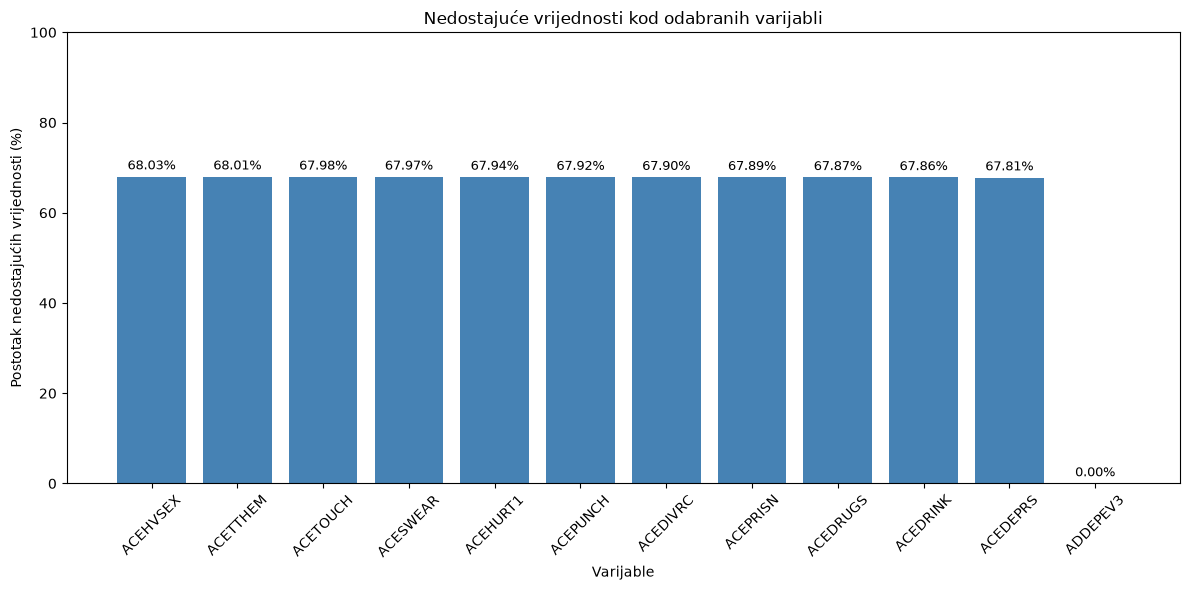

In [8]:
ace_nedostajuci = nedostajuci[
    nedostajuci["Varijabla"].str.startswith("ACE") |
    (nedostajuci["Varijabla"] == "ADDEPEV3")
]

display(ace_nedostajuci)

plt.figure(figsize=(12, 6))

stupci = plt.bar(
    ace_nedostajuci["Varijabla"],
    ace_nedostajuci["Postotak nedostajucih"],
    color="steelblue"
)

plt.bar_label(stupci, fmt="%.2f%%", padding=3, fontsize=9)

plt.title("Nedostajuće vrijednosti kod odabranih varijabli")
plt.xlabel("Varijable")
plt.ylabel("Postotak nedostajućih vrijednosti (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("grafikon_1.png", dpi=300)
plt.show()

## 2.3. Provjera potpunosti zapisa

In [9]:
ace_kolone = [c for c in df.columns if c.startswith("ACE")]

odabrane_kolone = ace_kolone + ["ADDEPEV3"]

potpunost = pd.DataFrame({
    "Obuhvat analize": [
        "Sve varijable",
        "ACE varijable i ADDEPEV3"
    ],
    "Potpuno popunjeni zapisi": [
        df.notna().all(axis=1).sum(),
        df[odabrane_kolone].notna().all(axis=1).sum()
    ],
    "Nepotpuni zapisi": [
        df.isna().any(axis=1).sum(),
        df[odabrane_kolone].isna().any(axis=1).sum()
    ]
})

display(potpunost)

print("Zapisi bez ijednog ACE odgovora:",
      df[ace_kolone].isna().all(axis=1).sum())

print("Udio potpuno popunjenih odabranih zapisa:",
      round(df[odabrane_kolone].notna().all(axis=1).mean() * 100, 2), "%")

,Obuhvat analize,Potpuno popunjeni zapisi,Nepotpuni zapisi
0,Sve varijable,0,401958
1,ACE varijable i ADDEPEV3,128496,273462


Zapisi bez ijednog ACE odgovora: 272569
Udio potpuno popunjenih odabranih zapisa: 31.97 %


## 2.4. Provjera duplikata

In [10]:
broj_duplikata = df.duplicated().sum()

print("Broj potpuno jednakih redova:", broj_duplikata)

print("Postotak duplikata:",
      round(broj_duplikata / len(df) * 100, 2), "%")

Broj potpuno jednakih redova: 0
Postotak duplikata: 0.0 %


## 2.5. Provjera nelogičnih i neusklađenih vrijednosti

### Provjera posebnih kodova odgovora

In [11]:
for kolona in odabrane_kolone:
    print("\nVarijabla:", kolona)
    display(df[kolona].value_counts(dropna=False).sort_index().to_frame("Broj odgovora"))

posebni_odgovori = pd.DataFrame({
    "Varijabla": odabrane_kolone,
    "Ne znam (7)": [(df[k] == 7).sum() for k in odabrane_kolone],
    "Roditelji nisu bili u braku (8)": [
        (df[k] == 8).sum() if k == "ACEDIVRC" else "-"
        for k in odabrane_kolone
    ],
    "Odbijam odgovoriti (9)": [(df[k] == 9).sum() for k in odabrane_kolone]
})

display(posebni_odgovori)


Varijabla: ACEDEPRS


,Broj odgovora
ACEDEPRS,
1.0,20591
2.0,106213
7.0,985
9.0,1597
NaN,272572



Varijabla: ACEDRINK


,Broj odgovora
ACEDRINK,
1.0,28269
2.0,99004
7.0,439
9.0,1493
NaN,272753



Varijabla: ACEDRUGS


,Broj odgovora
ACEDRUGS,
1.0,12165
2.0,115022
7.0,546
9.0,1406
NaN,272819


... (15 outputs left out)

,Broj odgovora
ACEHVSEX,
1.0,119727
2.0,2030
3.0,3843
7.0,361
9.0,2538
NaN,273459



Varijabla: ADDEPEV3


,Broj odgovora
ADDEPEV3,
1.0,75820
2.0,324035
7.0,1476
9.0,621
NaN,6


,Varijabla,Ne znam (7),Roditelji nisu bili u braku (8),Odbijam odgovoriti (9)
0,ACEDEPRS,985,-,1597
1,ACEDRINK,439,-,1493
2,ACEDRUGS,546,-,1406
3,ACEPRISN,280,-,1406
4,ACEDIVRC,668,1621,1547
5,ACEPUNCH,1688,-,2113
6,ACEHURT1,732,-,2273
7,ACESWEAR,1379,-,2239
8,ACETOUCH,402,-,2646
9,ACETTHEM,457,-,2519


### Provjera valjanih odgovora

In [12]:
popunjeni = df[odabrane_kolone].notna().all(axis=1)

posebni_kodovi = df[odabrane_kolone].isin([7, 9]).any(axis=1)

valjani = popunjeni & ~posebni_kodovi

print("Potpuno popunjeni zapisi:",
      popunjeni.sum())

print("Popunjeni zapisi s kodovima 7 ili 9:",
      (popunjeni & posebni_kodovi).sum())

print("Zapisi sa svim valjanim odgovorima:",
      valjani.sum())

print("Udio valjanih zapisa u izvornom datasetu:",
      round(valjani.sum() / len(df) * 100, 2), "%")

Potpuno popunjeni zapisi: 128496
Popunjeni zapisi s kodovima 7 ili 9: 11158
Zapisi sa svim valjanim odgovorima: 117338
Udio valjanih zapisa u izvornom datasetu: 29.19 %


### Provjera numeričkih vrijednosti

In [13]:
numericke_kolone = [
    "_AGE80",
    "SLEPTIM1",
    "MENTHLTH",
    "PHYSHLTH",
    "HTM4",
    "WTKG3",
    "_BMI5"
]

numericki_pregled = pd.DataFrame({
    "Varijabla": numericke_kolone,
    "Minimum": [df[k].min() for k in numericke_kolone],
    "Maksimum": [df[k].max() for k in numericke_kolone]
})

display(numericki_pregled)

,Varijabla,Minimum,Maksimum
0,_AGE80,18.0,80.0
1,SLEPTIM1,1.0,99.0
2,MENTHLTH,1.0,99.0
3,PHYSHLTH,1.0,99.0
4,HTM4,91.0,241.0
5,WTKG3,2268.0,29030.0
6,_BMI5,1202.0,9843.0


### Provjera raspona vrijednosti

In [14]:
print("Dob izvan dozvoljenog raspona:",
      (df["_AGE80"].notna() &
       ~df["_AGE80"].between(18, 80)).sum())

for kolona in ["SLEPTIM1", "MENTHLTH", "PHYSHLTH"]:
    print("\nVarijabla:", kolona)
    display(
        df[kolona].value_counts().sort_index()
        .to_frame("Broj zapisa")
    )

Dob izvan dozvoljenog raspona: 0

Varijabla: SLEPTIM1


,Broj zapisa
SLEPTIM1,
1.0,762
2.0,1102
3.0,2680
4.0,9985
5.0,24431
6.0,82622
7.0,118786
8.0,122257
9.0,19836



Varijabla: MENTHLTH


,Broj zapisa
MENTHLTH,
1.0,11144
2.0,19591
3.0,12500
4.0,6344
5.0,16705
6.0,1794
7.0,6524
8.0,1314
9.0,252



Varijabla: PHYSHLTH


,Broj zapisa
PHYSHLTH,
1.0,12492
2.0,17864
3.0,10371
4.0,5396
5.0,9192
6.0,1531
7.0,5692
8.0,1149
9.0,234


### Provjera jedinica mjere

In [15]:
display(
    df[["HEIGHT3", "HTM4", "WEIGHT2",
        "WTKG3", "_BMI5"]].head(10)
)

,HEIGHT3,HTM4,WEIGHT2,WTKG3,_BMI5
0,507.0,170.0,106.0,4808.0,1660.0
1,504.0,163.0,170.0,7711.0,2918.0
2,508.0,173.0,7777.0,NaN,NaN
3,9999.0,NaN,9999.0,NaN,NaN
4,506.0,168.0,126.0,5715.0,2034.0
5,509.0,175.0,180.0,8165.0,2658.0
6,506.0,168.0,150.0,6804.0,2421.0
7,503.0,160.0,150.0,6804.0,2657.0
8,511.0,180.0,170.0,7711.0,2371.0
9,503.0,160.0,163.0,7394.0,2887.0


### Provjera datumskih vrijednosti

In [16]:
datumi = pd.to_datetime(
    df["IDATE"].str.decode("utf-8"),
    format="%m%d%Y",
    errors="coerce"
)

print("Neispravni datumi:",
      (df["IDATE"].notna() & datumi.isna()).sum())

print("Najraniji datum:", datumi.min())
print("Najkasniji datum:", datumi.max())

mjeseci = pd.to_numeric(df["IMONTH"], errors="coerce")
dani = pd.to_numeric(df["IDAY"], errors="coerce")
godine = pd.to_numeric(df["IYEAR"], errors="coerce")

neuskladjeni_datumi = datumi.notna() & (
    (datumi.dt.month != mjeseci) |
    (datumi.dt.day != dani) |
    (datumi.dt.year != godine)
)

print("Neuskladjeni datumski zapisi:",
      neuskladjeni_datumi.sum())

Neispravni datumi: 0
Najraniji datum: 2020-01-02 00:00:00
Najkasniji datum: 2021-03-18 00:00:00
Neuskladjeni datumski zapisi: 0


### Provjera usklađenosti BMI vrijednosti

In [17]:
visina = df["HTM4"] / 100
tezina = df["WTKG3"] / 100

izracunati_bmi = tezina / (visina ** 2)
evidentirani_bmi = df["_BMI5"] / 100

razlika = (izracunati_bmi - evidentirani_bmi).abs()

print("Broj uporedivih BMI zapisa:",
      razlika.notna().sum())

print("Najveca razlika:", razlika.max())

print("Broj odstupanja vecih od 1:",
      (razlika > 1).sum())

Broj uporedivih BMI zapisa: 360601
Najveca razlika: 0.865558507426627
Broj odstupanja vecih od 1: 0


## 2.6. Analiza obrazaca nedostajanja podataka

### Nedostajanje ACE podataka prema državi, spolu i dobnoj grupi

In [18]:
bez_ace = df[ace_kolone].isna().all(axis=1)

obrasci = pd.DataFrame({
    "Drzava": df["_STATE"],
    "Spol": df["SEXVAR"],
    "Dobna grupa": df["_AGEG5YR"],
    "Bez ACE podataka": bez_ace
})

for grupa in ["Drzava", "Spol", "Dobna grupa"]:
    rezultat = obrasci.groupby(grupa)["Bez ACE podataka"].agg(
        ["count", "sum", "mean"]
    )

    rezultat.columns = [
        "Ukupno ispitanika",
        "Bez ACE podataka",
        "Postotak nedostajucih"
    ]

    rezultat["Postotak nedostajucih"] = (
        rezultat["Postotak nedostajucih"] * 100
    ).round(2)

    print("\nNedostajuci ACE podaci prema:", grupa)
    display(rezultat)

    rezultat.to_csv(
        "nedostajuci_ACE_" + grupa.replace(" ", "_") + ".csv"
    )


Nedostajuci ACE podaci prema: Drzava


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Drzava,,,
1.0,5341,775,14.51
2.0,3675,3675,100.00
4.0,10291,2009,19.52
5.0,5244,5244,100.00
6.0,4798,4798,100.00
8.0,10184,10184,100.00
9.0,8982,8982,100.00
10.0,4025,4025,100.00
11.0,3428,654,19.08



Nedostajuci ACE podaci prema: Spol


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Spol,,,
1.0,183942,125489,68.22
2.0,218016,147080,67.46



Nedostajuci ACE podaci prema: Dobna grupa


,Ukupno ispitanika,Bez ACE podataka,Postotak nedostajucih
Dobna grupa,,,
1.0,25648,17788,69.35
2.0,20911,14854,71.03
3.0,23408,16293,69.60
4.0,25492,17380,68.18
5.0,25729,17471,67.90
6.0,26428,18117,68.55
7.0,31110,21579,69.36
8.0,36219,24920,68.80
9.0,41151,27982,68.00


### Grafički prikaz nedostajanja ACE podataka prema području anketiranja

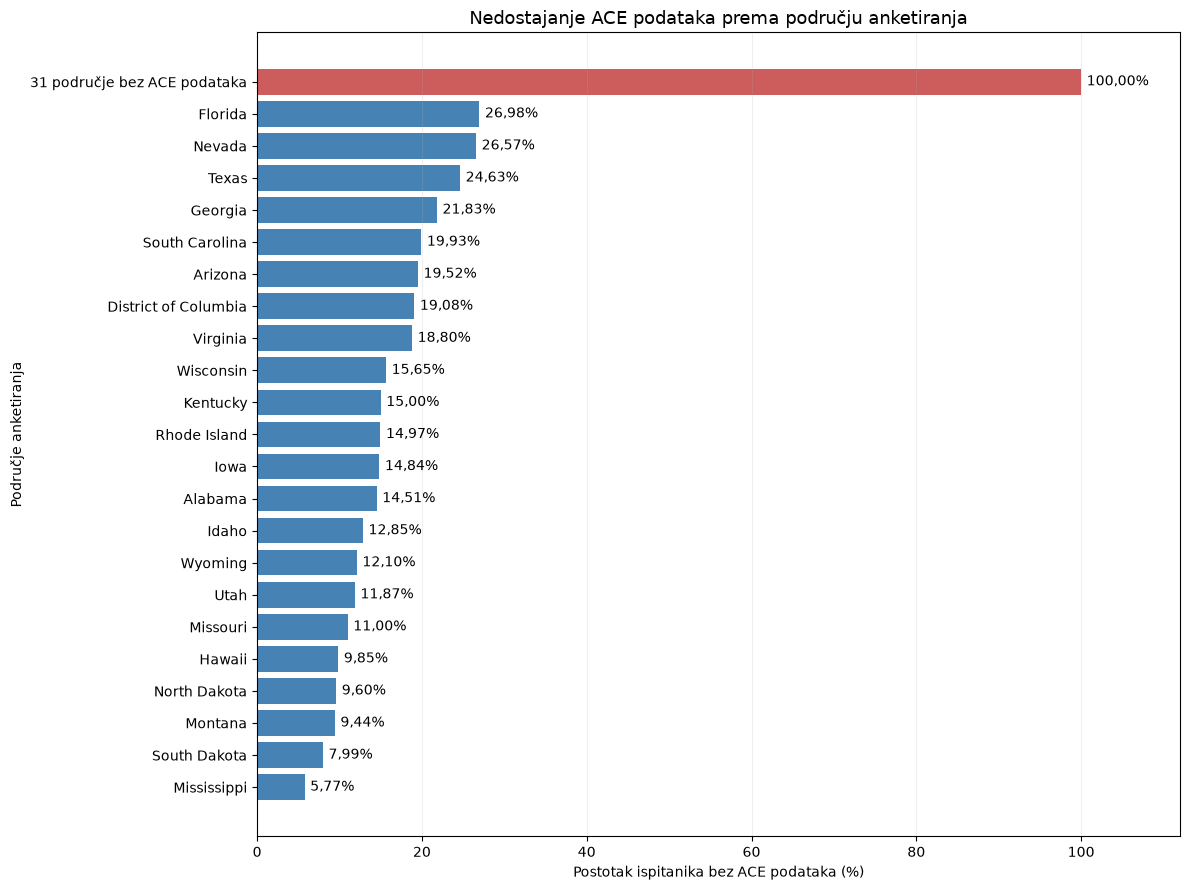

In [19]:
nazivi_drzava = {
    1: "Alabama",
    4: "Arizona",
    11: "District of Columbia",
    12: "Florida",
    13: "Georgia",
    15: "Hawaii",
    16: "Idaho",
    19: "Iowa",
    21: "Kentucky",
    28: "Mississippi",
    29: "Missouri",
    30: "Montana",
    32: "Nevada",
    38: "North Dakota",
    44: "Rhode Island",
    45: "South Carolina",
    46: "South Dakota",
    48: "Texas",
    49: "Utah",
    51: "Virginia",
    55: "Wisconsin",
    56: "Wyoming"
}

nedostajanje_drzave = (
    obrasci.groupby("Drzava")["Bez ACE podataka"]
    .mean() * 100
)

potpuno_nedostaju = (nedostajanje_drzave == 100).sum()

prikaz = nedostajanje_drzave[
    nedostajanje_drzave < 100
].copy()

prikaz.index = prikaz.index.map(
    lambda x: nazivi_drzava.get(int(x), str(int(x)))
)

prikaz[f"{potpuno_nedostaju} područje bez ACE podataka"] = 100

prikaz = prikaz.sort_values()

boje = [
    "indianred" if x == 100 else "steelblue"
    for x in prikaz.values
]

plt.figure(figsize=(12, 9))

stupci = plt.barh(
    prikaz.index,
    prikaz.values,
    color=boje
)

plt.bar_label(
    stupci,
    labels=[
        f"{x:.2f}%".replace(".", ",")
        for x in prikaz.values
    ],
    padding=4,
    fontsize=10
)

plt.title(
    "Nedostajanje ACE podataka prema području anketiranja",
    fontsize=13
)

plt.xlabel("Postotak ispitanika bez ACE podataka (%)")
plt.ylabel("Područje anketiranja")
plt.xlim(0, 112)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

plt.savefig("grafikon_2.png", dpi=300)
plt.show()

# 3. Razvrstavanje varijabli prema mjernoj ljestvici

Razvrstavanje varijabli izvršeno je na osnovu njihovog značenja i službene Codebook dokumentacije. Numerički zapis varijable ne znači nužno da je ona kvantitativna.

In [20]:
klasifikacija = pd.read_csv("klasifikacija_279_varijabli.csv")

display(klasifikacija.head(10))

print("Broj klasifikovanih varijabli:", len(klasifikacija))

print("Neklasifikovane varijable:",
      set(df.columns) - set(klasifikacija["Varijabla"]))

print("Varijable koje nisu u datasetu:",
      set(klasifikacija["Varijabla"]) - set(df.columns))

print("Ponovljene varijable:",
      klasifikacija["Varijabla"].duplicated().sum())

print("Nazivi kolona:", klasifikacija.columns.tolist())

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,_STATE,State FIPS Code,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
1,FMONTH,File Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
2,IDATE,Interview Date,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
3,IMONTH,Interview Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
4,IDAY,Interview Day,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
5,IYEAR,Interview Year,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
6,DISPCODE,Final Disposition,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
7,SEQNO,Annual Sequence Number,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
8,_PSU,Primary Sampling Unit,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
9,CTELENM1,Correct telephone number?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN


Broj klasifikovanih varijabli: 279
Neklasifikovane varijable: set()
Varijable koje nisu u datasetu: set()
Ponovljene varijable: 0
Nazivi kolona: ['Varijabla', 'Opis (Codebook)', 'Mjerna ljestvica', 'Obrazlozenje', 'Prirodni redoslijed', 'Napomena']


### Pregled broja varijabli prema mjernoj ljestvici

In [21]:
display(
    klasifikacija["Mjerna ljestvica"]
    .value_counts()
    .to_frame("Broj varijabli")
)

print("Broj praznih mjernih ljestvica:",
      klasifikacija["Mjerna ljestvica"].isna().sum())

,Broj varijabli
Mjerna ljestvica,
Nominalne,180
Ordinalne,45
Kvantitativne – diskretne,29
Kvantitativne – kontinuirane,15
Datumske i datumske komponente,7
Identifikacijske i tehničke oznake,3


Broj praznih mjernih ljestvica: 0


## 3.1. Nominalne varijable



In [22]:
nominalne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Nominalne"
]

display(nominalne.reset_index(drop=True))

print("Broj nominalnih varijabli:", len(nominalne))

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,_STATE,State FIPS Code,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
1,DISPCODE,Final Disposition,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
2,CTELENM1,Correct telephone number?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
3,PVTRESD1,Private Residence?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
4,COLGHOUS,Do you live in college housing?,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
...,...,...,...,...,...,...
175,_STOLDNA,Respondents aged 50-75 who have had a stool DN...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
176,_VIRCOLN,Respondents aged 50-75 who have had a virtual ...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
177,_SBONTIM,Respondents aged 50-75 who have had a sigmoido...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN
178,_CRCREC1,Respondents aged 50-75 who have fully met the ...,Nominalne,Kodovi predstavljaju kategorije bez jednoznačn...,NaN,NaN


Broj nominalnih varijabli: 180


## 3.2. Ordinalne varijable



In [23]:
ordinalne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Ordinalne"
]

display(ordinalne.reset_index(drop=True))

print("Broj ordinalnih varijabli:", len(ordinalne))

,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,GENHLTH,General Health,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",1 → 2 → 3 → 4 → 5 (odličan → loš),NaN
1,PERSDOC2,Multiple Health Care Professionals,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 1 → 2 (nijedan → jedan → više),NaN
2,CHECKUP1,Length of time since last routine checkup,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
3,LASTDEN4,Last Visited Dentist or Dental Clinic,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
4,RMVTETH4,Number of Permanent Teeth Removed,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",8 → 1 → 2 → 3 (nijedan → svi),NaN
5,EDUCA,Education Level,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od najnižeg do najvišeg nivoa,NaN
6,INCOME2,Income Level,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od najnižeg do najvišeg nivoa,NaN
7,SMOKDAY2,Frequency of Days Now Smoking,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 2 → 1 (nikada/sada ne → neki dani → svaki ...,NaN
8,LASTSMK2,Interval Since Last Smoked,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",Od kraćeg do dužeg vremena; nikada odvojeno ak...,NaN
9,USENOW3,Use of Smokeless Tobacco Products,Ordinalne,"Kategorije imaju prirodan redoslijed, ali razm...",3 → 2 → 1 (nikada/sada ne → neki dani → svaki ...,NaN


Broj ordinalnih varijabli: 45


## 3.3. Kvantitativne varijable



In [24]:
diskretne = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Kvantitativne – diskretne"
]

kontinuirane = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Kvantitativne – kontinuirane"
]

print("Diskretne varijable:")
display(diskretne.reset_index(drop=True))

print("Kontinuirane varijable:")
display(kontinuirane.reset_index(drop=True))

print("Broj diskretnih varijabli:", len(diskretne))
print("Broj kontinuiranih varijabli:", len(kontinuirane))
print("Ukupan broj kvantitativnih varijabli:",
      len(diskretne) + len(kontinuirane))

Diskretne varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,NUMADULT,Number of Adults in Household,Kvantitativne – diskretne,Broj odraslih; gornja grupa objedinjena u izvj...,NaN,NaN
1,NUMMEN,Number of Adult men in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
2,NUMWOMEN,Number of Adult women in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
3,HHADULT,Number of Adults in Household,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
4,PHYSHLTH,Number of Days Physical Health Not Good,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
5,MENTHLTH,Number of Days Mental Health Not Good,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
6,POORHLTH,Poor Physical or Mental Health,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
7,SLEPTIM1,How Much Time Do You Sleep,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
8,DIABAGE3,Age When Told Had Diabetes,Kvantitativne – diskretne,Predstavlja prebrojivu količinu ili vrijednost...,NaN,NaN
9,NUMPHON3,Residential Phones,Kvantitativne – diskretne,Broj telefona; 6 znači šest ili više.,NaN,NaN


Kontinuirane varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,WEIGHT2,Reported Weight in Pounds,Kvantitativne – kontinuirane,Masa uz kodiranu jedinicu (lb/kg).,NaN,NaN
1,HEIGHT3,Reported Height in Feet and Inches,Kvantitativne – kontinuirane,Visina uz kodiranu jedinicu (stope/inči ili me...,NaN,NaN
2,_STRWT,Stratum weight,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
3,_RAWRAKE,Raw weighting factor used in raking,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
4,_WT2RAKE,Design weight use in raking,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
5,_CLLCPWT,Final child weight: Land-line and Cell-Phone data,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
6,_DUALCOR,Dual Phone Use Correction Factor,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
7,_LLCPWT2,Truncated design weight used in adult combined...,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
8,_LLCPWT,Final weight: Land-line and cell-phone data,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,Tehnička namjena; ne koristiti nekritički u an...
9,HTIN4,Computed Height in Inches,Kvantitativne – kontinuirane,Predstavlja mjerljivu ili izračunatu numeričku...,NaN,NaN


Broj diskretnih varijabli: 29
Broj kontinuiranih varijabli: 15
Ukupan broj kvantitativnih varijabli: 44


## 3.4. Varijable posebne namjene



In [25]:
datumske = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Datumske i datumske komponente"
]

identifikacijske = klasifikacija[
    klasifikacija["Mjerna ljestvica"] == "Identifikacijske i tehničke oznake"
]

print("Datumske varijable:")
display(datumske.reset_index(drop=True))

print("Identifikacijske i tehničke oznake:")
display(identifikacijske.reset_index(drop=True))

print("Broj datumskih varijabli:", len(datumske))
print("Broj identifikacijskih i tehnickih oznaka:", len(identifikacijske))

Datumske varijable:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,FMONTH,File Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
1,IDATE,Interview Date,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
2,IMONTH,Interview Month,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
3,IDAY,Interview Day,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
4,IYEAR,Interview Year,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
5,FLSHTMY3,When did you receive your most recent seasonal...,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN
6,HIVTSTD3,Month and Year of Last HIV Test,Datumske i datumske komponente,Predstavlja datum ili njegovu vremensku kompon...,NaN,NaN


Identifikacijske i tehničke oznake:


,Varijabla,Opis (Codebook),Mjerna ljestvica,Obrazlozenje,Prirodni redoslijed,Napomena
0,SEQNO,Annual Sequence Number,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
1,_PSU,Primary Sampling Unit,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...
2,_STSTR,Sample Design Stratification Variable,Identifikacijske i tehničke oznake,Oznaka zapisa ili uzorkovanja; ne predstavlja ...,NaN,Tehnička namjena; ne koristiti nekritički u an...


Broj datumskih varijabli: 7
Broj identifikacijskih i tehnickih oznaka: 3


## 3.5. Sažeti pregled nivoa mjerenja varijabli



In [26]:
sazetak_mjerenja = pd.DataFrame({
    "Vrsta varijable": [
        "Nominalne",
        "Ordinalne",
        "Kvantitativne – diskretne",
        "Kvantitativne – kontinuirane",
        "Datumske i datumske komponente",
        "Identifikacijske i tehničke oznake",
        "Ukupno"
    ],
    "Broj varijabli": [
        len(nominalne),
        len(ordinalne),
        len(diskretne),
        len(kontinuirane),
        len(datumske),
        len(identifikacijske),
        len(klasifikacija)
    ]
})

display(sazetak_mjerenja)

,Vrsta varijable,Broj varijabli
0,Nominalne,180
1,Ordinalne,45
2,Kvantitativne – diskretne,29
3,Kvantitativne – kontinuirane,15
4,Datumske i datumske komponente,7
5,Identifikacijske i tehničke oznake,3
6,Ukupno,279
